In [226]:
import numpy as np
import numba as nb
import scipy.stats as stats
import torch
import matplotlib.pyplot as plt
import pickle
import yaml
from sbi.utils.sbiutils import gradient_ascent

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.utils.user_input_checks import process_simulator
from sbi.inference.posteriors import DirectPosterior

In [228]:
from functools import partial
import sys
sys.path.append('../src')

from simulator import smFRET_simulator_wrapper_from_config
from priors import generate_posterior_prior_from_config
from utils import eval_spline_from_config

In [229]:
data_cfg = "../conf/simulator/highnodes.yaml"

In [230]:
prior = generate_posterior_prior_from_config(data_cfg, device="cuda")
eval_spline = eval_spline_from_config(data_cfg)

In [231]:
def bin_along_time(x, n_bins=100):
    n = len(x)
    n_per_bin = int(n / n_bins)
    x_binned = np.zeros(n_bins)
    for i in range(n_bins):
        x_binned[i] = np.sum(x[i*n_per_bin:(i+1)*n_per_bin])
    return x_binned

In [232]:
fret_simulator = smFRET_simulator_wrapper_from_config(data_cfg)

In [215]:
true_params = torch.tensor([ 
    -0.100, -1.5938, -1.7873, -1.5556,  1.1016, -2.1840,  10.0000, 5.0, 0.0500,  0.0500,  0.7500,  0.7500,  0.9000,  0.9000,  0.1000,  0.1000
], dtype=torch.float64)
true_params[1:5] = true_params[1:5] - true_params[1:5].mean()

In [216]:
observation = torch.stack([fret_simulator(true_params) for _ in range(1)])

Text(0.5, 0, 'Time')

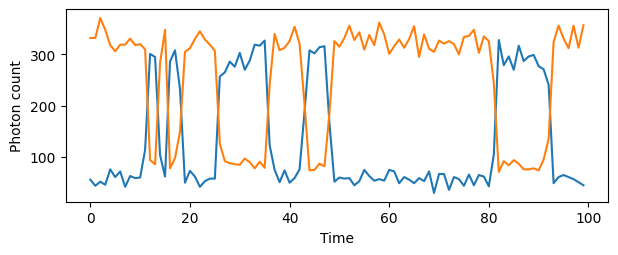

In [225]:
idx = 0
plt.figure(figsize=(7, 2.5))
plt.plot(bin_along_time(observation[idx, :,0].numpy(), n_bins=100), label="Donor")
plt.plot(bin_along_time(observation[idx, :,1].numpy(), n_bins=100), label="acceptor")
plt.ylabel("Photon count")
plt.xlabel("Time")


In [218]:
with open("/home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/density_estimator/2026-03-03/18-22-53/density_estimator.pkl", "rb") as f:
    density_estimator = pickle.load(f)
density_estimator = density_estimator.cuda()

In [219]:
posterior = DirectPosterior(density_estimator, prior=prior)
samples = posterior.sample((100000,), x=observation.cuda()).cpu()

100833it [00:00, 807390.87it/s]                           


In [220]:
posterior.set_default_x(observation.cuda())
map_estimate = posterior.map(
    num_iter=1_000,
    num_to_optimize=1,
    learning_rate=0.01,
    init_method="posterior",
    num_init_samples=100,
    save_best_every=10,
    show_progress_bars=False,
    force_update=False,
)


196it [00:00, 17681.88it/s]            


/tmp/ipykernel_909157/2935610074.py:1: DeprecationWarning: you passed deprecated arguments **kwargs: ['points_offdiag', 'points_colors'], use fig_kwargs instead. We continue calling the deprecated pairplot function
  _ = analysis.pairplot(


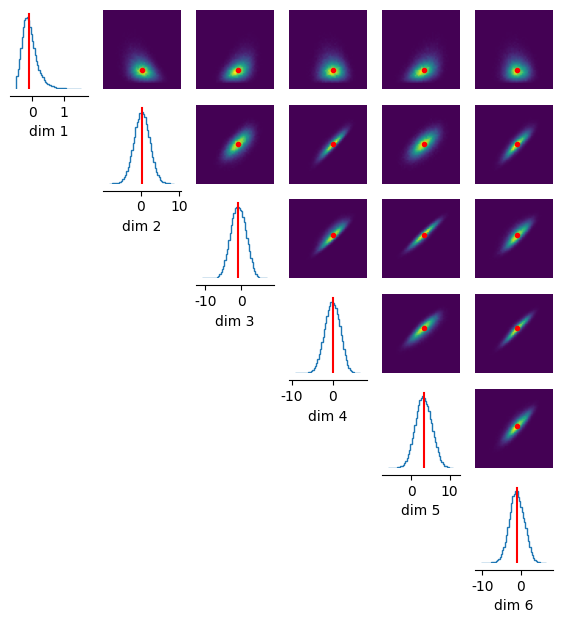

In [221]:
_ = analysis.pairplot(
    samples,
    figsize=(7,7),
    points=map_estimate[0].cpu(), 
    points_offdiag={'markersize': 6},
    points_colors='r', 
)

In [222]:
samples[:, 1:] = samples[:, 1:] - samples[:, 1:].mean(dim=1, keepdim=True)
map_estimate[1:] = map_estimate[1:] - map_estimate[1:].mean()

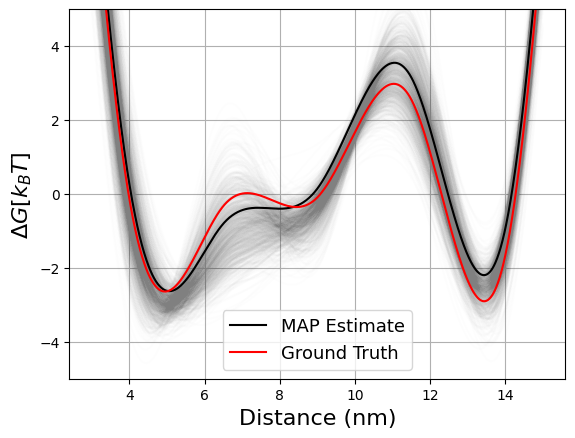

In [223]:
for i in range(1000):
    x, y = eval_spline(
        params=samples[i],
        x_eval=np.linspace(3, 15, 1000),
    )
    plt.plot(x, y, color='gray', alpha=0.01)
x, y = eval_spline(
    params=map_estimate[0].cpu(),
    x_eval=np.linspace(3, 15, 1000),
)
plt.plot(x, y, color='black', label='MAP Estimate')
x, y = eval_spline(
    params=true_params,
    x_eval=np.linspace(3, 15, 1000),
)
plt.plot(x, y+0.5, color='r', label='Ground Truth')
plt.xlabel("Distance (nm)", fontsize=16)
plt.ylabel(r"$\Delta G [k_{B}T]$", fontsize=16)
plt.ylim(-5, 5)
plt.grid()
plt.legend(fontsize=13)

Text(0, 0.5, 'p(log(D)|x)')

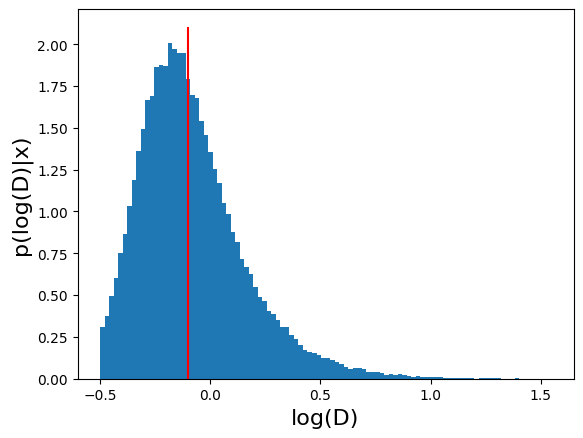

In [224]:
plt.hist(samples[:, 0].numpy(), bins=100, density=True)
plt.vlines(true_params[0], ymin=0, ymax=plt.gca().get_ylim()[1], color='r', label='Ground Truth')
plt.xlabel("log(D)", fontsize=16)
plt.ylabel("p(log(D)|x)", fontsize=16)